# 25 Leave-group-out retraining: which joints carry information the others do not?

**Why this notebook.** Notebook 23 removed joints from trained models at test time. That showed which joints the model leans on,
but the accuracy drops were huge (head removal took validation accuracy from 77% to about 13%) because the model had never seen
an input like that. This notebook asks the cleaner question: **if a group of joints is removed from the input for both
training and evaluation, so the model can adapt, how much accuracy is lost?** A group whose removal costs little is redundant,
the information is available elsewhere. A group whose removal costs a lot carries information the rest of the body does not.

**Arms.** Everything is the stage 1 control (ST-GCN with velocity, balanced sampler, cross entropy, tuned recipe, advanced
augmentation), tuning seeds 77 and 88, except that a group of joints is removed from the input. A removed joint has
confidence zero and its position replaced by the mean position of the remaining joints, exactly as in notebook 23. The racket side
of each clip is the wrist with the larger confidence weighted path length, computed once from the clean clip.

| arm | removed | joints |
|---|---|---|
| `control` | nothing (the stage 1 runs, reused) | 0 |
| `no_racket_arm` | racket-side shoulder, elbow, wrist | 3 |
| `no_off_arm` | the other shoulder, elbow, wrist | 3 |
| `no_arms` | both arms | 6 |
| `no_head` | nose, eyes, ears | 5 |
| `no_lower_body` | hips, knees, ankles | 6 |

`no_racket_arm` against `no_off_arm` is a like for like comparison (same size, same position in the body).

**Two rules, fixed before running.**

1. *A group carries information of its own* if removing it lowers mean validation top-1 by at least **1.5 points** (about
   twice the 0.85 seed noise floor) and no single seed drops by less than 0.5.
2. *A group carries information specific to the confusable shots* if the per clip accuracy lost on clips of the confusable
   classes (the seven classes from notebook 23: Lift, Block, Drop Shot, Push Shot, Cut, Smash, Flat Shot) exceeds the loss on the
   other clips by at least **3 points**, and the 95% bootstrap interval of that difference (clips resampled within each
   group) excludes zero.

**Reading it.**
- If `no_racket_arm` costs about the same as `no_off_arm` and neither passes rule 1, the arm joints are redundant, and a
  pathway dedicated to them has nothing to recover.
- If `no_head` passes rule 2, the head carries what separates the confusable shots, which would be a design lead (a model that
  uses head position and orientation more explicitly) and worth reporting in itself.
- If nothing costs anything, the information is spread redundantly over the body and the ceiling is the input.

Validation only, no test data, no clip duration. Logs to `BadmintonPoseAnalysis/experiments/leave_group_out`.

In [10]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task
from torch.utils.data import DataLoader

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [11]:
PROJECT = "BadmintonPoseAnalysis/experiments/leave_group_out"
KEYPOINTS = f"{DATA}/keypoints_interp"
STAGE1_OUT = f"{OUTPUTS}/experiments/model5_stage1_graph"
OUT = f"{OUTPUTS}/experiments/leave_group_out"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]
SPLITS = ("train", "val")          # the test set is never evaluated
NORMALISATION, USE_COURT, USE_VELOCITY = "body", True, True
NUM_WORKERS, EVAL_WORKERS = 20, 8
MIN_DROP, MIN_SEED_DROP, MIN_SPECIFIC, N_BOOT = 0.015, 0.005, 0.03, 2000

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
with open(f"{REPO}/configs/model5_stage1.json") as f:
    VEL_SCALE = json.load(f)["velocity_scale"]
with open(f"{REPO}/configs/joint_ablation.json") as f:
    CONFUSABLE_NAMES = json.load(f)["confusable_classes"]
print("recipe:", RECIPE)
print("confusable classes:", CONFUSABLE_NAMES)

J = {n: i for i, n in enumerate(ds.JOINT_NAMES)}
HEAD = [J[n] for n in ("nose", "l_eye", "r_eye", "l_ear", "r_ear")]
LOWER = [J[n] for n in ("l_hip", "r_hip", "l_knee", "r_knee", "l_ankle", "r_ankle")]
ARM = {"l": [J["l_shoulder"], J["l_elbow"], J["l_wrist"]], "r": [J["r_shoulder"], J["r_elbow"], J["r_wrist"]]}
ARMS = ["no_racket_arm", "no_off_arm", "no_arms", "no_head", "no_lower_body"]
SIZES = {"no_racket_arm": 3, "no_off_arm": 3, "no_arms": 6, "no_head": 5, "no_lower_body": 6}
rng = np.random.RandomState(0)

recipe: {'model': 'ST-GCN', 'normalisation': 'body_court', 'selected': 'combination', 'changes_from_baseline': {'weight_decay': 0.005, 'target_per_class': 300}, 'augmentation': 'advanced', 'min_native_frames': 5, 'batch_size': 16, 'lr': 0.01, 'momentum': 0.9, 'gamma': 0.1, 'select_metric': 'top1', 'weight_decay': 0.005, 'label_smoothing': 0.0, 'schedule': 'step10', 'target_per_class': 300, 'num_epochs': 60, 'patience': 20, 'tuning': {'seeds': [11, 22], 'val_top1': 0.7612, 'baseline_val_top1': 0.7394}}
confusable classes: ['Lift', 'Block', 'Drop Shot', 'Push Shot', 'Cut', 'Smash', 'Flat Shot']


In [12]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", 5)
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
short = [c.split("_", 1)[-1] for c in class_names]
confusable = [short.index(n) for n in CONFUSABLE_NAMES]
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
in_channels = stgcn_model.n_channels(USE_COURT, USE_VELOCITY)

# racket side per clip from the clean clip (the wrist with the larger confidence weighted path length), train and val
clean = ds.BadmintonPoseDataset(manifest[manifest["split"].isin(SPLITS)].reset_index(drop=True), KEYPOINTS, class_to_id, "none", NORMALISATION)
RIGHT = {}
for batch in DataLoader(clean, batch_size=256, shuffle=False, num_workers=EVAL_WORKERS):
    kp = batch["keypoints"].float()
    step = (kp[:, 1:, :, :2] - kp[:, :-1, :, :2]).norm(dim=-1)
    w = torch.minimum(kp[:, 1:, :, 2], kp[:, :-1, :, 2])
    speed = (step * w).sum(1) / w.sum(1).clamp(min=1e-6)
    for p, r in zip(batch["filepath"], (speed[:, J["r_wrist"]] > speed[:, J["l_wrist"]]).tolist()):
        RIGHT[p] = r
print(f"racket side known for {len(RIGHT)} clips, right in {np.mean(list(RIGHT.values())):.1%}")


def group_mask(paths, group):
    """(n, 17) boolean numpy mask, True where the joint is removed."""
    n = len(paths)
    mask = np.zeros((n, ds.NUM_JOINTS), dtype=bool)
    right = np.array([RIGHT[p] for p in paths])
    racket = np.where(right[:, None], ARM["r"], ARM["l"])
    off = np.where(right[:, None], ARM["l"], ARM["r"])
    rows = np.arange(n)[:, None]
    if group in ("no_racket_arm", "no_arms"):
        mask[rows, racket] = True
    if group in ("no_off_arm", "no_arms"):
        mask[rows, off] = True
    if group == "no_head":
        mask[:, HEAD] = True
    if group == "no_lower_body":
        mask[:, LOWER] = True
    return mask


PARENT = torch.as_tensor(ds.PARENT, dtype=torch.long)
BASE_FORWARD = stgcn_model.make_forward(USE_COURT, USE_VELOCITY, VEL_SCALE)


def apply_mask(kp, court, mask):
    keep = (~mask)[:, None, :, None].float()
    mean_xy = (kp[..., :2] * keep).sum(2, keepdim=True) / keep.sum(2, keepdim=True).clamp(min=1.0)
    xy = torch.where(mask[:, None, :, None], mean_xy.expand_as(kp[..., :2]), kp[..., :2])
    conf = torch.where(mask[:, None, :], torch.zeros_like(kp[..., 2]), kp[..., 2])
    bone = xy - xy[:, :, PARENT.to(kp.device), :]
    return {"keypoints": torch.cat([xy, conf[..., None]], dim=-1), "bone": bone, "court": court}


def make_forward(group):
    def forward(model, batch, device):
        kp, court = batch["keypoints"].float().to(device), batch["court"].float().to(device)
        mask = torch.as_tensor(group_mask(batch["filepath"], group), device=device)
        return BASE_FORWARD(model, apply_mask(kp, court, mask), device)
    return forward

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)
racket side known for 7028 clips, right in 63.8%


## Smoke test

A mask that removes nothing must change nothing; each group must have the intended size and remove the right joints; a gradient
must reach every parameter through the masked input; the stage 1 control predictions used as the control arm must exist
for both seeds.

In [13]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2)
batch = next(iter(loaders["train"]))
paths = list(batch["filepath"])
kp, court = batch["keypoints"].float().to(device), batch["court"].float().to(device)

none = torch.zeros((len(paths), ds.NUM_JOINTS), dtype=torch.bool, device=device)
same = apply_mask(kp, court, none)
assert torch.equal(same["keypoints"], kp) and torch.allclose(same["bone"], batch["bone"].float().to(device), atol=1e-5)

rows = []
for group in ARMS:
    m = group_mask(paths, group)
    assert (m.sum(1) == SIZES[group]).all(), group
    out = apply_mask(kp, court, torch.as_tensor(m, device=device))
    assert (out["keypoints"][..., 2][torch.as_tensor(m, device=device)[:, None, :].expand(-1, kp.shape[1], -1)] == 0).all()
    model = stgcn_model.build_stgcn(in_channels, K).to(device)
    logits = make_forward(group)(model, batch, device)
    assert logits.shape == (len(paths), K)
    nn.CrossEntropyLoss()(logits, batch["label"].to(device)).backward()
    assert not [n for n, p in model.named_parameters() if p.requires_grad and p.grad is None]
    rows.append({"arm": group, "joints removed per clip": int(m.sum(1)[0]), "parameters": sum(p.numel() for p in model.parameters())})
    del model
print(pd.DataFrame(rows).to_string(index=False))
head_ids = group_mask(paths, "no_head")[0].nonzero()[0].tolist()
assert head_ids == sorted(HEAD)
for s in SEEDS:
    assert os.path.exists(f"{STAGE1_OUT}/model5s1_control_s{s}/model5s1_control_s{s}_predictions.csv"), f"missing control seed {s}"
del loaders
print("smoke test passed")

          arm  joints removed per clip  parameters
no_racket_arm                        3     3028735
   no_off_arm                        3     3028735
      no_arms                        6     3028735
      no_head                        5     3028735
no_lower_body                        6     3028735
smoke test passed


In [14]:
results_path = f"{OUT}/results.csv"
done = pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])

for group in ARMS:
    for seed in SEEDS:
        if ((done["config"] == group) & (done["seed"] == seed)).any():
            print(f"skip {group} seed {seed}, already done")
            continue
        run_name = f"lgo_{group}_s{seed}"
        print(f"\n=== {run_name} ===")
        tr.seed_everything(seed)
        task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                         tags=["leave_group_out", group, f"seed{seed}"], reuse_last_task_id=False,
                         auto_connect_frameworks={"matplotlib": False, "pytorch": False})
        task.connect({**RECIPE, "removed": group, "joints_removed": SIZES[group], "input": "body_court_velocity",
                      "in_channels": in_channels, "velocity_scale": VEL_SCALE, "seed": seed, "keypoints": KEYPOINTS,
                      "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})
        loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=seed,
                                   batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                                   num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
        forward = make_forward(group)
        model = stgcn_model.build_stgcn(in_channels, K).to(device)
        optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                    weight_decay=RECIPE["weight_decay"])
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
        criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])
        _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                                task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                                patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                                splits=SPLITS)
        metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                                out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                                extra={"config": group, "seed": seed})
        task.close()
        done = pd.concat([done, pd.DataFrame([metrics])], ignore_index=True)
        done.to_csv(results_path, index=False)
        del model, loaders
        torch.cuda.empty_cache()

skip no_racket_arm seed 77, already done
skip no_racket_arm seed 88, already done
skip no_off_arm seed 77, already done
skip no_off_arm seed 88, already done
skip no_arms seed 77, already done
skip no_arms seed 88, already done
skip no_head seed 77, already done
skip no_head seed 88, already done
skip no_lower_body seed 77, already done
skip no_lower_body seed 88, already done


## Results

The control is the stage 1 control runs (same configuration and seeds), reused rather than retrained.

In [15]:
def val_predictions(path):
    d = pd.read_csv(path)
    d = d[d["split"] == "val"].sort_values("filepath").reset_index(drop=True)
    return d["filepath"].to_numpy(), d["label"].map(class_to_id).to_numpy(), d["pred"].map(class_to_id).to_numpy()


def val_paths(group, seed):
    if group == "control":
        return f"{STAGE1_OUT}/model5s1_control_s{seed}/model5s1_control_s{seed}_predictions.csv"
    return f"{OUT}/lgo_{group}_s{seed}/lgo_{group}_s{seed}_predictions.csv"


files, labels, pred = None, None, {}
for group in ["control"] + ARMS:
    for s in SEEDS:
        f, y, yh = val_predictions(val_paths(group, s))
        files, labels = (f, y) if files is None else (files, labels)
        assert (f == files).all() and (y == labels).all(), (group, s)
        pred[(group, s)] = yh
correct = {k: (v == labels).astype(float) for k, v in pred.items()}
is_conf = np.isin(labels, confusable)

stage1 = pd.read_csv(f"{STAGE1_OUT}/results.csv")
res = pd.read_csv(results_path)
rows = []
for group in ["control"] + ARMS:
    src = stage1[stage1["config"] == "control"] if group == "control" else res[res["config"] == group]
    src = src.set_index("seed").loc[SEEDS]
    rows.append({"arm": group, "removed joints": 0 if group == "control" else SIZES[group],
                 "val top1": 100 * src["val_top1"].mean(), "val mca": 100 * src["val_mca"].mean(),
                 "train val gap": 100 * (src["train_top1"] - src["val_top1"]).mean(),
                 "top1 seed 77": 100 * src.loc[77, "val_top1"], "top1 seed 88": 100 * src.loc[88, "val_top1"]})
table = pd.DataFrame(rows).set_index("arm")
base = table.loc["control"]
table["d top1"] = table["val top1"] - base["val top1"]
table["d mca"] = table["val mca"] - base["val mca"]
table["d top1 seed 77"] = table["top1 seed 77"] - base["top1 seed 77"]
table["d top1 seed 88"] = table["top1 seed 88"] - base["top1 seed 88"]
table["carries information (rule 1)"] = [(a != "control") and (-r["d top1"] >= 100 * MIN_DROP) and
                                         (-r["d top1 seed 77"] >= 100 * MIN_SEED_DROP) and (-r["d top1 seed 88"] >= 100 * MIN_SEED_DROP)
                                         for a, r in table.iterrows()]
table.round(2)

,removed joints,val top1,val mca,train val gap,top1 seed 77,top1 seed 88,d top1,d mca,d top1 seed 77,d top1 seed 88,carries information (rule 1)
arm,,,,,,,,,,,
control,0,76.76,67.75,20.02,76.44,77.08,0.00,0.00,0.00,0.00,False
no_racket_arm,3,74.33,64.81,21.77,74.90,73.75,-2.43,-2.94,-1.54,-3.33,True
no_off_arm,3,74.78,65.16,18.26,73.50,76.06,-1.98,-2.60,-2.94,-1.02,True
no_arms,6,74.52,65.51,19.23,74.01,75.03,-2.24,-2.24,-2.43,-2.05,True
no_head,5,74.78,64.53,19.58,75.03,74.52,-1.98,-3.23,-1.41,-2.56,True
no_lower_body,6,74.33,66.25,21.53,74.65,74.01,-2.43,-1.50,-1.79,-3.07,True


In [16]:
# per clip accuracy lost against the control (seed averaged), split into confusable and other clips
c_control = np.mean([correct[("control", s)] for s in SEEDS], axis=0)
rows = []
lost = {}
for group in ARMS:
    lost[group] = c_control - np.mean([correct[(group, s)] for s in SEEDS], axis=0)
    a, b = lost[group][is_conf], lost[group][~is_conf]
    diffs = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(N_BOOT)]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({"arm": group, "lost on confusable clips (pts)": 100 * a.mean(), "lost on other clips (pts)": 100 * b.mean(),
                 "difference (pts)": 100 * (a.mean() - b.mean()), "ci_lo": 100 * lo, "ci_hi": 100 * hi,
                 "specific to confusable (rule 2)": bool((a.mean() - b.mean()) >= MIN_SPECIFIC and lo > 0)})
specific = pd.DataFrame(rows).set_index("arm")
specific_show = specific.assign(**{"95% CI": [f"[{a:+.1f}, {b:+.1f}]" for a, b in zip(specific["ci_lo"], specific["ci_hi"])]}
                                ).drop(columns=["ci_lo", "ci_hi"]).round(1)
print(f"{is_conf.sum()} confusable validation clips, {(~is_conf).sum()} other clips")
specific_show

402 confusable validation clips, 379 other clips


,lost on confusable clips (pts),lost on other clips (pts),difference (pts),specific to confusable (rule 2),95% CI
arm,,,,,
no_racket_arm,3.6,1.2,2.4,False,"[-1.1, +5.9]"
no_off_arm,2.7,1.2,1.5,False,"[-1.9, +5.1]"
no_arms,4.4,0.0,4.4,True,"[+0.9, +8.0]"
no_head,2.5,1.5,1.0,False,"[-2.2, +4.4]"
no_lower_body,4.4,0.4,4.0,True,"[+0.2, +7.6]"


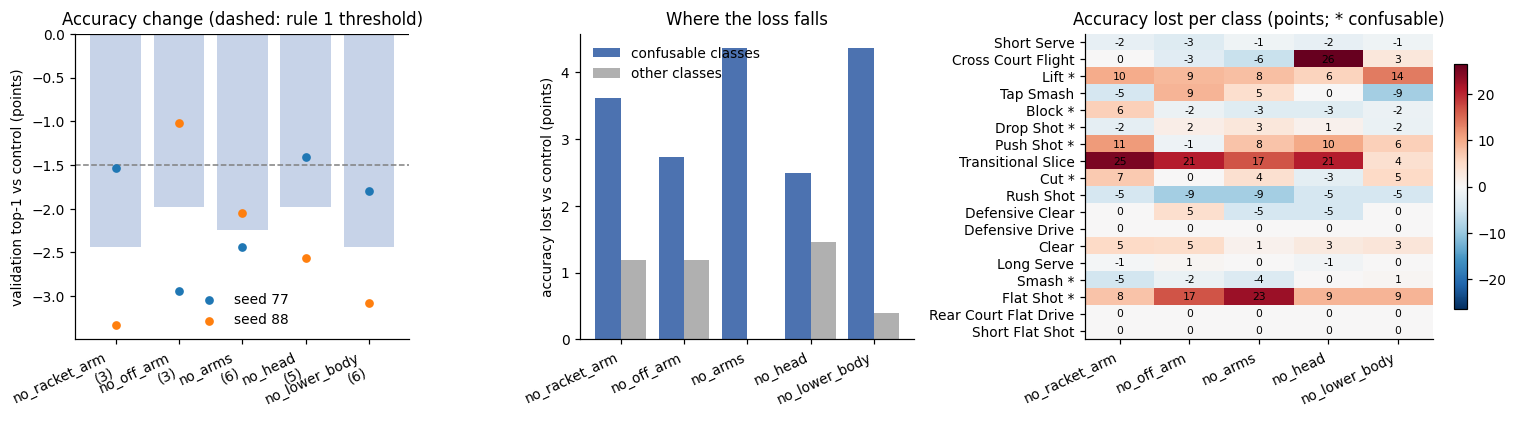

,no_racket_arm,no_off_arm,no_arms,no_head,no_lower_body,clips,confusable
Short Serve,-2.3,-3.4,-1.1,-2.3,-1.1,88,False
Cross Court Flight,0.0,-2.9,-5.9,26.5,2.9,17,False
Lift,9.9,8.6,7.9,5.9,13.8,76,True
Tap Smash,-4.5,9.1,4.5,0.0,-9.1,11,False
Block,6.2,-1.6,-3.1,-3.1,-1.6,32,True
Drop Shot,-2.5,1.9,3.1,1.2,-1.9,81,True
Push Shot,11.2,-1.2,7.5,10.0,6.2,40,True
Transitional Slice,25.0,20.8,16.7,20.8,4.2,12,False
Cut,6.9,0.0,4.3,-2.6,5.2,58,True
Rush Shot,-4.5,-9.1,-9.1,-4.5,-4.5,11,False


In [17]:
per_class = pd.DataFrame({g: [100 * lost[g][labels == k].mean() for k in range(K)] for g in ARMS}, index=short)
per_class["clips"] = [int((labels == k).sum()) for k in range(K)]
per_class["confusable"] = [k in confusable for k in range(K)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1, 1.3]})
x = np.arange(len(ARMS))
ax = axes[0]
for i, s in enumerate(SEEDS):
    ax.scatter(x, [table.loc[g, f"d top1 seed {s}"] for g in ARMS], s=22, label=f"seed {s}", zorder=3)
ax.bar(x, [table.loc[g, "d top1"] for g in ARMS], color="#c7d3e8", zorder=1)
ax.axhline(-100 * MIN_DROP, color="grey", ls="--", lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x, [f"{g}\n({SIZES[g]})" for g in ARMS], rotation=25, ha="right")
ax.set_ylabel("validation top-1 vs control (points)")
ax.set_title("Accuracy change (dashed: rule 1 threshold)")
ax.legend(frameon=False)
ax = axes[1]
ax.bar(x - 0.2, specific["lost on confusable clips (pts)"], 0.4, label="confusable classes", color="#4c72b0")
ax.bar(x + 0.2, specific["lost on other clips (pts)"], 0.4, label="other classes", color="#b0b0b0")
ax.set_xticks(x, ARMS, rotation=25, ha="right")
ax.set_ylabel("accuracy lost vs control (points)")
ax.set_title("Where the loss falls")
ax.legend(frameon=False)
ax = axes[2]
mat = per_class[ARMS].to_numpy()
lim = np.abs(mat).max()
im = ax.imshow(mat, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(ARMS)), ARMS, rotation=25, ha="right")
ax.set_yticks(range(K), [f"{n} *" if k in confusable else n for k, n in enumerate(short)])
for (i, j), v in np.ndenumerate(mat):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Accuracy lost per class (points; * confusable)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()
per_class.round(1)

In [18]:
informative = [g for g in ARMS if table.loc[g, "carries information (rule 1)"]]
specific_to = [g for g in ARMS if specific.loc[g, "specific to confusable (rule 2)"]]
print("rule 1, groups whose removal costs at least 1.5 points (both seeds):", informative or "none")
print("rule 2, groups whose removal costs the confusable shots at least 3 points more than the rest:", specific_to or "none")
arm_gap = table.loc["no_racket_arm", "d top1"] - table.loc["no_off_arm", "d top1"]
print(f"racket arm vs off arm removal, top-1 change difference: {arm_gap:+.2f} points")

task = Task.init(project_name=PROJECT, task_name="leave_group_out_summary", task_type=Task.TaskTypes.qc,
                 tags=["leave_group_out", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
log = task.get_logger()
task.connect({**RECIPE, "seeds": SEEDS, "rules": {"min_drop": MIN_DROP, "min_seed_drop": MIN_SEED_DROP, "min_specific": MIN_SPECIFIC},
              "confusable_classes": CONFUSABLE_NAMES, "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})
log.report_table("accuracy by removed group (validation)", "val", iteration=0, table_plot=table.round(2).reset_index())
log.report_table("confusable vs other clips", "val", iteration=0, table_plot=specific_show.reset_index())
log.report_table("per class accuracy lost", "val", iteration=0, table_plot=per_class.round(1).reset_index().rename(columns={"index": "class"}))
log.report_matplotlib_figure("leave group out", "val", figure=fig, iteration=0, report_interactive=False)

decision = {"experiment": "leave_group_out", "groups_carrying_information": informative, "groups_specific_to_confusable": specific_to,
            "racket_vs_off_arm_top1_difference": round(float(arm_gap), 2),
            "top1_change_by_group": {g: round(float(table.loc[g, "d top1"]), 2) for g in ARMS},
            "rules": {"min_drop_points": 100 * MIN_DROP, "min_seed_drop_points": 100 * MIN_SEED_DROP, "min_specific_points": 100 * MIN_SPECIFIC}}
with open(f"{REPO}/configs/leave_group_out.json", "w") as f:
    json.dump(decision, f, indent=2)
task.upload_artifact("decision", artifact_object=f"{REPO}/configs/leave_group_out.json")
task.upload_artifact("results", artifact_object=results_path)
task.close()
decision

rule 1, groups whose removal costs at least 1.5 points (both seeds): ['no_racket_arm', 'no_off_arm', 'no_arms', 'no_head', 'no_lower_body']
rule 2, groups whose removal costs the confusable shots at least 3 points more than the rest: ['no_arms', 'no_lower_body']
racket arm vs off arm removal, top-1 change difference: -0.45 points


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=1a9bad3b14964da2963a9e25b42afbf7
ClearML results page: https://app.clear.ml/projects/5d576558995e486e8a2dbc2b7dba5d8c/tasks/1a9bad3b14964da2963a9e25b42afbf7/output/log


{'experiment': 'leave_group_out',
 'groups_carrying_information': ['no_racket_arm',
  'no_off_arm',
  'no_arms',
  'no_head',
  'no_lower_body'],
 'groups_specific_to_confusable': ['no_arms', 'no_lower_body'],
 'racket_vs_off_arm_top1_difference': -0.45,
 'top1_change_by_group': {'no_racket_arm': -2.43,
  'no_off_arm': -1.98,
  'no_arms': -2.24,
  'no_head': -1.98,
  'no_lower_body': -2.43},
 'rules': {'min_drop_points': 1.5,
  'min_seed_drop_points': 0.5,
  'min_specific_points': 3.0}}

## Reading the result

- **Rule 1 passes for a group**: the other joints do not make up for it, so it carries information of its own. A drop of a
  few points is evidence; with two seeds and 781 validation clips, anything under about 1.5 points is not distinguishable from
  seed noise.
- **Racket arm against off arm.** Same size, same position in the body. A clear gap between them says the racket arm matters more
  than the arm that only balances the body; no gap says the arm joints in general are redundant.
- **Rule 2 passes for a group**: its removal hurts the confusable shots more than the rest, so the cue separating them is there.
  For the head that would motivate a design that models head position and orientation explicitly. It would still not show the model
  uses the cue badly, only that it is needed.
- **Nothing passes.** The information is spread redundantly over the body, which supports the claim that the ceiling is set by
  the input and not by the architecture, and a hybrid has no specific cue to exploit.
- **Caveats.** Two seeds only; validation has been used throughout; the racket side is a heuristic (wrongly assigned for some
  clips where both wrists move alike); the interval treats clips as independent, although clips from one match are not.
  A removed joint is filled with the mean of the others, so its velocity channels carry that mean's motion, not zero.